# Notebook 05 — Uplift Modeling & Heterogeneous Treatment Effects

**What uplift modeling does:** Instead of estimating a single average treatment effect, uplift models estimate the *individual-level* causal effect — the **conditional average treatment effect (CATE)** — for each customer. This enables *targeting*: send the campaign only to customers where the incremental lift exceeds the cost.

**Methods covered:**
- **T-Learner:** Train separate models for treated and control; CATE = µ₁(x) - µ₀(x)
- **S-Learner:** Single model with treatment indicator as a feature
- **Uplift decile analysis:** Rank customers by predicted CATE; evaluate actual lift by decile
- **Qini curve:** Cumulative gain chart measuring targeting efficiency vs. random
- **Heterogeneous effects:** Who responds most / least to the campaign


In [1]:
import sys, os
sys.path.insert(0, os.path.join(os.path.dirname(os.getcwd()), 'src'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.calibration import CalibratedClassifierCV

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 120})

FEATURE_COLS = ['recency', 'log_history', 'mens', 'womens', 'newbie',
                'channel_web', 'channel_multi', 'zip_urban', 'zip_suburban']

df = pd.read_csv('../data/hillstrom_clean.csv')

# Focus on Mens Email vs Control for this notebook
df_study = df[df['segment'].isin(['No E-Mail', 'Mens E-Mail'])].copy().reset_index(drop=True)
X = df_study[FEATURE_COLS].values
T = df_study['treated'].values
Y = df_study['visit'].values

print(f'Study set: {len(df_study):,} rows  |  Treated: {T.sum():,}  |  Control: {(1-T).sum():,}')

Study set: 42,687 rows  |  Treated: 21,535  |  Control: 21,152


## 1. T-Learner

Mean CATE (T-Learner): 0.0557
Std  CATE (T-Learner): 0.0450


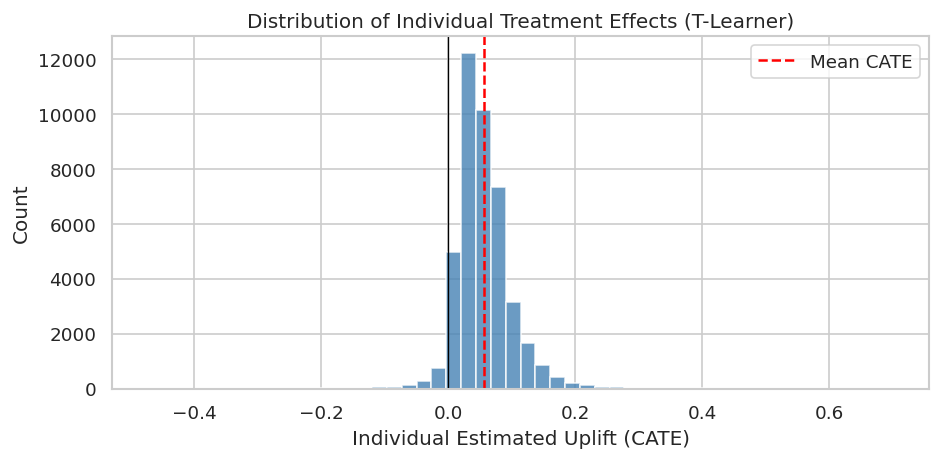

In [2]:
# Train separate models
gb_params = dict(n_estimators=150, max_depth=4, learning_rate=0.05, subsample=0.8, random_state=42)

model_1 = GradientBoostingClassifier(**gb_params)
model_0 = GradientBoostingClassifier(**gb_params)

X_t, y_t = X[T==1], Y[T==1]
X_c, y_c = X[T==0], Y[T==0]

model_1.fit(X_t, y_t)
model_0.fit(X_c, y_c)

# CATE = P(Y=1|X, T=1) - P(Y=1|X, T=0)
p1 = model_1.predict_proba(X)[:, 1]
p0 = model_0.predict_proba(X)[:, 1]
df_study['cate_t_learner'] = p1 - p0

print(f'Mean CATE (T-Learner): {df_study["cate_t_learner"].mean():.4f}')
print(f'Std  CATE (T-Learner): {df_study["cate_t_learner"].std():.4f}')

# Distribution of individual-level uplift
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df_study['cate_t_learner'], bins=50, color='steelblue', edgecolor='white', alpha=0.8)
ax.axvline(df_study['cate_t_learner'].mean(), color='red', linestyle='--', label=f'Mean CATE')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Individual Estimated Uplift (CATE)')
ax.set_ylabel('Count')
ax.set_title('Distribution of Individual Treatment Effects (T-Learner)')
ax.legend()
plt.tight_layout()
plt.savefig('../outputs/05_cate_distribution.png', bbox_inches='tight')
plt.show()

## 2. Uplift decile analysis
Rank customers by predicted CATE. Evaluate actual observed lift in each decile.

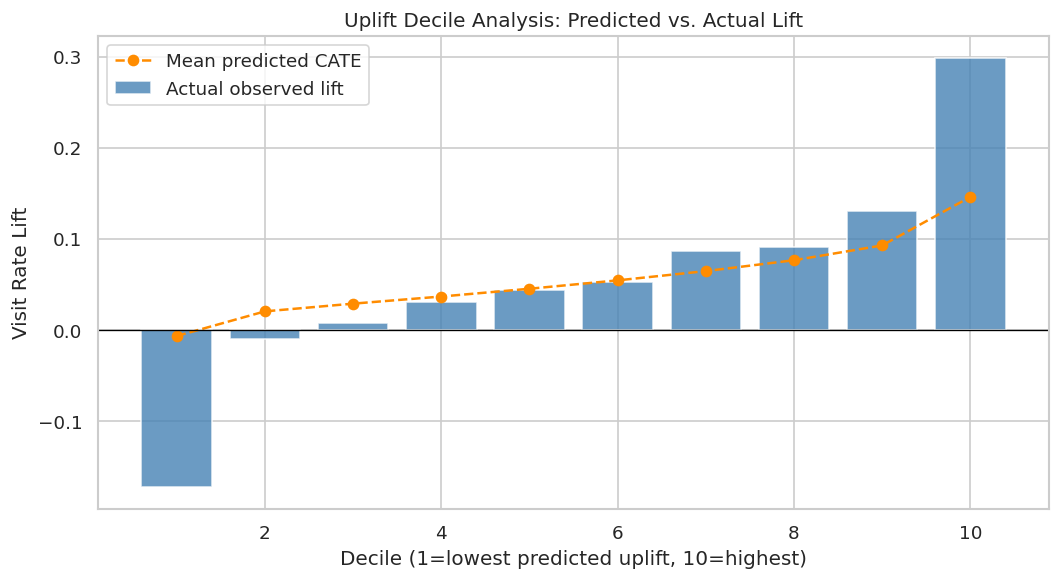

 decile  mean_predicted_cate  actual_lift    n
      1              -0.0069      -0.1727 4269
      2               0.0202      -0.0104 4269
      3               0.0287       0.0078 4268
      4               0.0365       0.0302 4270
      5               0.0450       0.0435 4268
      6               0.0542       0.0528 4268
      7               0.0644       0.0868 4269
      8               0.0764       0.0910 4270
      9               0.0926       0.1309 4267
     10               0.1459       0.2988 4269


In [3]:
df_study['cate_decile'] = pd.qcut(df_study['cate_t_learner'], 10, labels=False)

decile_results = []
for decile in range(10):
    sub = df_study[df_study['cate_decile'] == decile]
    t_rate = sub.loc[sub['treated']==1, 'visit'].mean() if (sub['treated']==1).any() else np.nan
    c_rate = sub.loc[sub['treated']==0, 'visit'].mean() if (sub['treated']==0).any() else np.nan
    decile_results.append({
        'decile': decile + 1,
        'mean_predicted_cate': sub['cate_t_learner'].mean(),
        'actual_lift': t_rate - c_rate if not np.isnan(t_rate) and not np.isnan(c_rate) else np.nan,
        'n': len(sub)
    })

decile_df = pd.DataFrame(decile_results)

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(decile_df['decile'], decile_df['actual_lift'], color='steelblue', alpha=0.8, label='Actual observed lift')
ax.plot(decile_df['decile'], decile_df['mean_predicted_cate'], 'o--', color='darkorange', label='Mean predicted CATE')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xlabel('Decile (1=lowest predicted uplift, 10=highest)')
ax.set_ylabel('Visit Rate Lift')
ax.set_title('Uplift Decile Analysis: Predicted vs. Actual Lift')
ax.legend()
plt.tight_layout()
plt.savefig('../outputs/05_uplift_deciles.png', bbox_inches='tight')
plt.show()

print(decile_df.round(4).to_string(index=False))

## 3. Qini curve (cumulative gain)

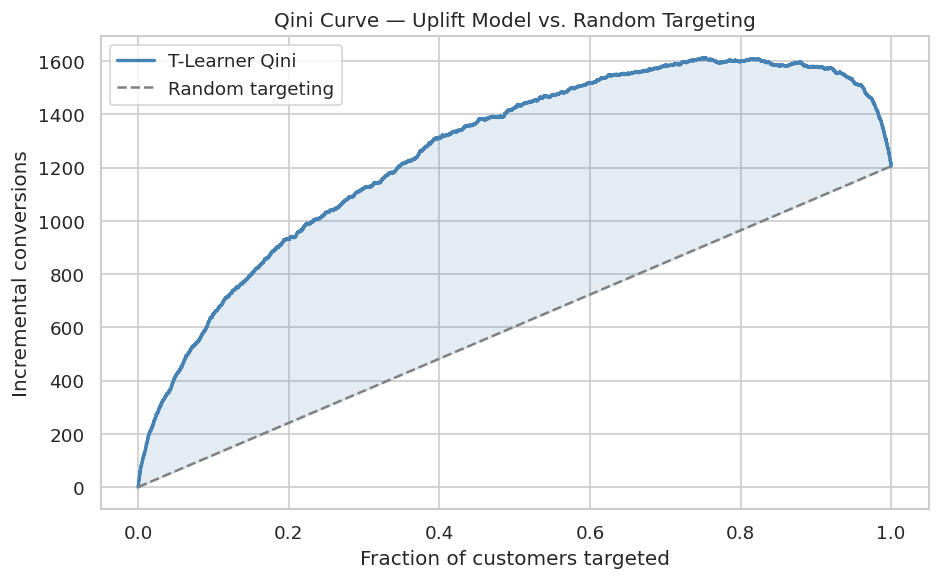

In [4]:
# Sort by predicted CATE descending
df_sorted = df_study.sort_values('cate_t_learner', ascending=False).reset_index(drop=True)

n = len(df_sorted)
n_t = df_sorted['treated'].sum()
n_c = n - n_t

# Cumulative incremental conversions
cum_treated    = df_sorted['treated'].cumsum()
cum_control    = (1 - df_sorted['treated']).cumsum()
cum_y_treated  = (df_sorted['treated'] * df_sorted['visit']).cumsum()
cum_y_control  = ((1-df_sorted['treated']) * df_sorted['visit']).cumsum()

# Qini: incremental conversions above random
qini = cum_y_treated - cum_y_control * (cum_treated / cum_control.replace(0, np.nan))
rand = np.linspace(0, qini.iloc[-1] if not np.isnan(qini.iloc[-1]) else 0, n)

x_axis = np.arange(1, n+1) / n

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x_axis, qini.values, color='steelblue', linewidth=2, label='T-Learner Qini')
ax.plot([0, 1], [0, qini.dropna().iloc[-1]], linestyle='--', color='grey', label='Random targeting')
ax.fill_between(x_axis, qini.values, rand, alpha=0.15, color='steelblue')
ax.set_xlabel('Fraction of customers targeted')
ax.set_ylabel('Incremental conversions')
ax.set_title('Qini Curve — Uplift Model vs. Random Targeting')
ax.legend()
plt.tight_layout()
plt.savefig('../outputs/05_qini_curve.png', bbox_inches='tight')
plt.show()

## 4. Who responds most? Feature importance for uplift

=== Mean CATE by Channel ===
              mean_cate  std_cate      n      se
channel                                         
Multichannel     0.0472    0.0430   8485  0.0005
Phone            0.0556    0.0449  12941  0.0004
Web              0.0592    0.0455  21261  0.0003


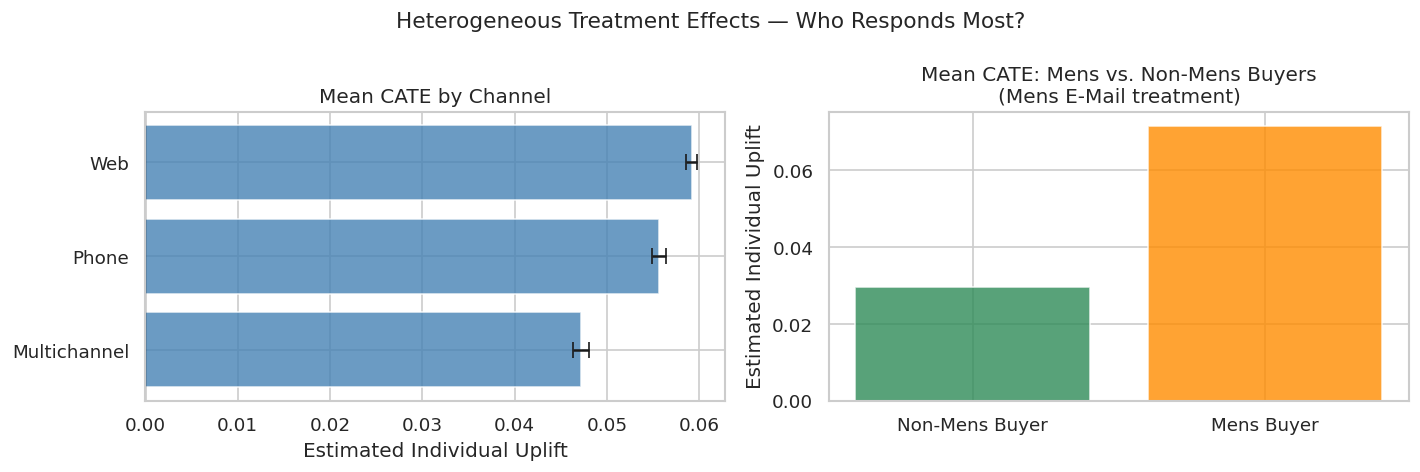

In [5]:
# Average CATE by customer segment to identify high-value targets
df_study['channel'] = np.where(df_study['channel_multi']==1, 'Multichannel',
                      np.where(df_study['channel_web']==1, 'Web', 'Phone'))

seg_cate = df_study.groupby('channel')['cate_t_learner'].agg(['mean','std','count'])
seg_cate.columns = ['mean_cate','std_cate','n']
seg_cate['se'] = seg_cate['std_cate'] / np.sqrt(seg_cate['n'])
print('=== Mean CATE by Channel ===')
print(seg_cate.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# By channel
axes[0].barh(seg_cate.index, seg_cate['mean_cate'],
             xerr=1.96*seg_cate['se'], capsize=5, color='steelblue', alpha=0.8)
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set_title('Mean CATE by Channel')
axes[0].set_xlabel('Estimated Individual Uplift')

# By product interest (mens flag)
cate_mens    = df_study.groupby('mens')['cate_t_learner'].mean()
cate_mens.index = ['Non-Mens Buyer', 'Mens Buyer']
axes[1].bar(cate_mens.index, cate_mens.values, color=['seagreen','darkorange'], alpha=0.8)
axes[1].set_title('Mean CATE: Mens vs. Non-Mens Buyers\n(Mens E-Mail treatment)')
axes[1].set_ylabel('Estimated Individual Uplift')

plt.suptitle('Heterogeneous Treatment Effects — Who Responds Most?', fontsize=13)
plt.tight_layout()
plt.savefig('../outputs/05_heterogeneous_cate.png', bbox_inches='tight')
plt.show()